# Width Investigation

Notebook for investigating the width workflow, including the double-transform diagnostics, bank-target inspection, and `_trim_slice` behavior.


These cells were split out of `rapid_hydrograph_analysis.ipynb` so the RAPID hydrograph notebook stays focused on hydrograph analysis.


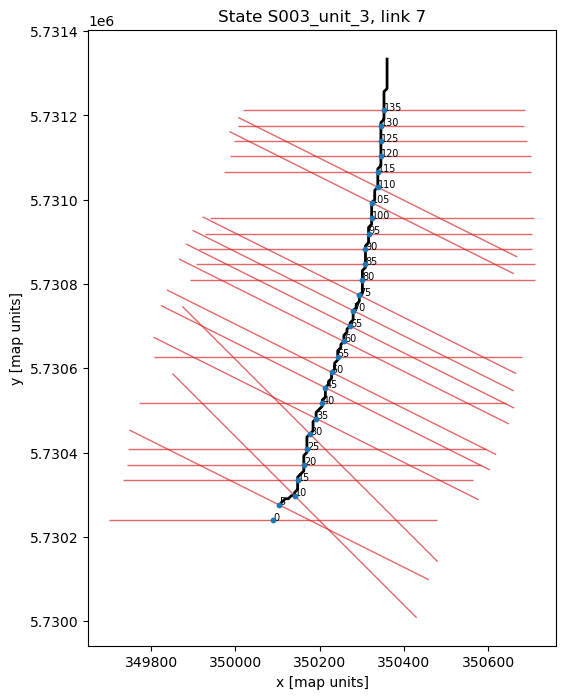

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import LineString

# --- choose state + link ---
state_dir = Path("/Users/6256481/Code/river-hierarchy/network_variants/output/56_indep__anchored/states/S003_unit_3/variant")
link_id = 7
sample_step = 5   # plot every Nth cross-section to reduce clutter
local = False     # True = rotate into local link coordinates

# --- load data ---
links = gpd.read_file(next((state_dir / "directed").glob("*_directed_links.gpkg")))
samples = pd.read_csv(state_dir / "widths" / "link_width_samples.csv")

link = links.loc[links["id_link"] == link_id].iloc[0]
s = samples.loc[samples["id_link"] == link_id].sort_values("sample_index").copy()

x = s["x"].to_numpy(dtype=float)
y = s["y"].to_numpy(dtype=float)
w = s["width_total"].to_numpy(dtype=float)

# --- local tangent from neighboring sample points ---
dx = np.gradient(x)
dy = np.gradient(y)
norm = np.hypot(dx, dy)
dx = np.where(norm > 0, dx / norm, 1.0)
dy = np.where(norm > 0, dy / norm, 0.0)

# perpendicular unit vectors
nx = -dy
ny = dx

# --- build measured cross-section segments ---
segments = []
for i in range(0, len(s), sample_step):
    half = w[i] / 2.0
    x0 = x[i] - nx[i] * half
    y0 = y[i] - ny[i] * half
    x1 = x[i] + nx[i] * half
    y1 = y[i] + ny[i] * half
    segments.append(
        {
            "sample_index": int(s.iloc[i]["sample_index"]),
            "width_total": float(w[i]),
            "n_wet_threads": int(s.iloc[i]["n_wet_threads"]),
            "geometry": LineString([(x0, y0), (x1, y1)]),
        }
    )

seg_gdf = gpd.GeoDataFrame(segments, geometry="geometry", crs=links.crs)
link_gdf = gpd.GeoDataFrame([link], geometry="geometry", crs=links.crs)
pts_gdf = gpd.GeoDataFrame(
    s.iloc[::sample_step][["sample_index", "width_total", "n_wet_threads"]].copy(),
    geometry=gpd.points_from_xy(x[::sample_step], y[::sample_step]),
    crs=links.crs,
)

# --- optional local-coordinate rotation ---
def rotate_xy(xs, ys, theta, x0, y0):
    xr = (xs - x0) * np.cos(theta) - (ys - y0) * np.sin(theta)
    yr = (xs - x0) * np.sin(theta) + (ys - y0) * np.cos(theta)
    return xr, yr

if local:
    theta = -np.arctan2(y[-1] - y[0], x[-1] - x[0])
    x0, y0 = x[0], y[0]

    def geom_to_local_coords(geom):
        if geom.geom_type == "LineString":
            coords = np.array(geom.coords)
            xr, yr = rotate_xy(coords[:, 0], coords[:, 1], theta, x0, y0)
            return LineString(np.c_[xr, yr])
        return geom

    link_gdf = link_gdf.copy()
    seg_gdf = seg_gdf.copy()
    pts_gdf = pts_gdf.copy()

    link_gdf["geometry"] = link_gdf.geometry.apply(geom_to_local_coords)
    seg_gdf["geometry"] = seg_gdf.geometry.apply(geom_to_local_coords)

    px, py = rotate_xy(pts_gdf.geometry.x.values, pts_gdf.geometry.y.values, theta, x0, y0)
    pts_gdf["geometry"] = gpd.points_from_xy(px, py, crs=links.crs)

# --- plot ---
fig, ax = plt.subplots(figsize=(10, 8))

link_gdf.plot(ax=ax, color="black", linewidth=2, zorder=3)
seg_gdf.plot(ax=ax, color="tab:red", linewidth=1, alpha=0.7, zorder=2)
pts_gdf.plot(ax=ax, color="tab:blue", markersize=10, zorder=4)

for row in pts_gdf.itertuples():
    ax.text(row.geometry.x, row.geometry.y, str(row.sample_index), fontsize=7)

ax.set_aspect("equal")
ax.set_title(f"State {state_dir.parent.name}, link {link_id}")
ax.set_xlabel("x [map units]" if not local else "local x [m]")
ax.set_ylabel("y [map units]" if not local else "local y [m]")
plt.show()


Link-level family row


,id_link,wid_adj,wid_adj_total,wid_adj_wet,wid_adj_dry,n_channels_max,n_wet_threads_max,n_invalid_width_samples,qc_mean_relative_dt_diff,qc_min_opposition_cos,width_method
66,41,510.897407,521.978901,512.480801,0.0,2,2,0,0.021789,-0.998774,two_bank_dt



Per-sample diagnostics


,sample_index,width_invalid,left_component_id,right_component_id,d_left,d_right,d_sum,width_total,width_wet,width_dry,width_chord,dt_width_global,qc_relative_dt_diff,qc_opposition_cos,qc_width_chord_diff
0,0,False,38,37,261.032535,241.915187,502.947723,502.947723,485.576182,0.0,19.456216,483.830375,0.039513,0.999897,0.961316
1,1,False,33,37,264.633154,254.125299,518.758453,518.758453,510.112996,0.0,399.302998,508.250598,0.020675,-0.184628,0.230272
2,2,False,33,37,261.177513,266.344162,527.521676,527.521676,518.944203,0.0,399.302998,522.355026,0.009891,-0.145839,0.243059
3,3,False,33,35,258.262494,276.935168,535.197662,535.197662,526.566175,0.0,531.407651,516.524989,0.036151,-0.971740,0.007082
4,4,False,33,35,255.906573,276.935168,532.841740,532.841740,524.177229,0.0,531.407651,511.813146,0.041086,-0.989232,0.002691
5,5,False,33,35,261.032535,270.714218,531.746753,531.746753,523.170480,0.0,530.409434,522.065071,0.018545,-0.989949,0.002515
6,6,False,33,35,259.578304,270.993737,530.572041,530.572041,521.944248,0.0,530.409434,519.156608,0.021988,-0.998774,0.000306
7,7,False,32,35,261.032535,265.204717,526.237252,526.237252,517.610412,0.0,358.438217,522.065071,0.007992,0.072180,0.318866
8,8,False,32,35,254.125299,259.578304,513.703603,513.703603,505.070089,0.0,358.438217,508.250598,0.010729,0.026397,0.302247
9,9,False,32,35,247.331293,252.930814,500.262107,500.262107,491.635998,0.0,321.940127,494.662585,0.011320,0.171852,0.356457


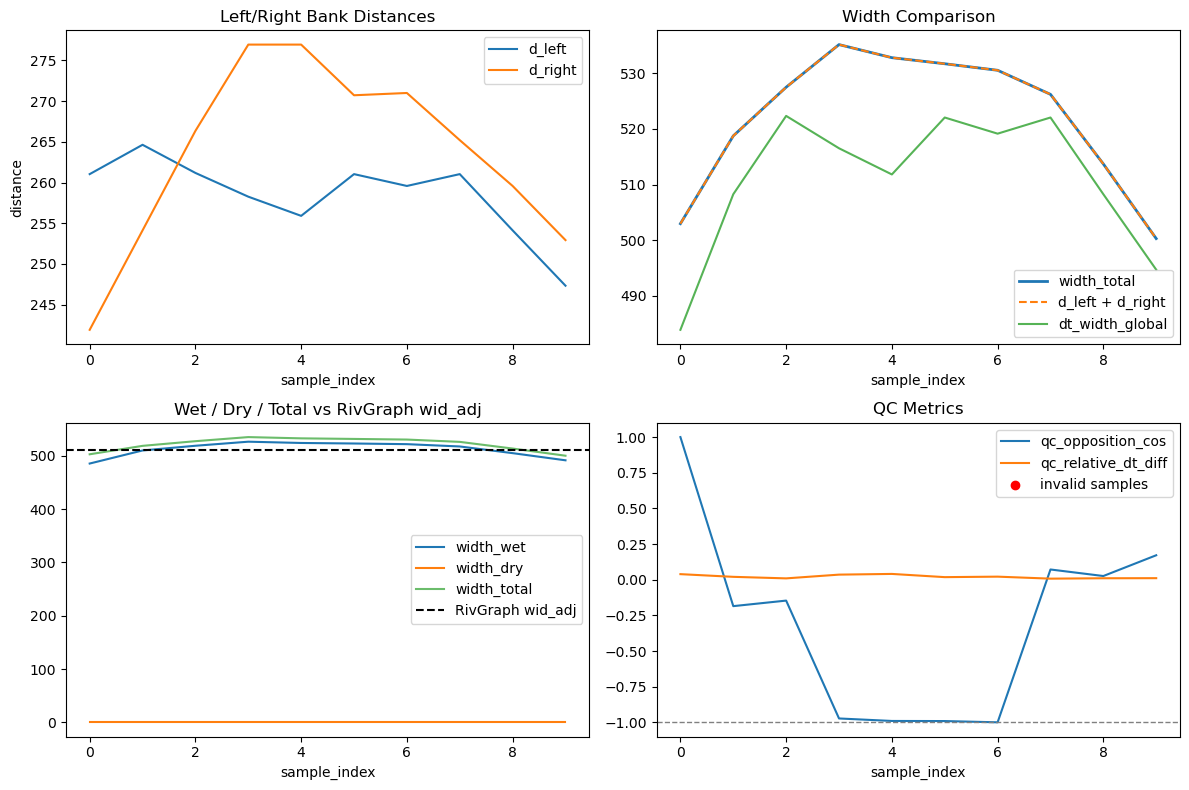

In [27]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# state_dir = Path("/Users/6256481/Code/river-hierarchy/network_variants/output/56_indep__anchored/states/S010_unit_8/variant")
# state_dir = Path("/Users/6256481/Code/river-hierarchy/network_variants/output/56_indep__anchored/states/S005_unit_7/variant")
# state_dir = Path("/Users/6256481/Code/river-hierarchy/network_variants/output/21_indep__anchored/states/S000_base/variant")
state_dir = Path("/Users/6256481/Code/river-hierarchy/network_variants/output/02_indep__anchored/states/S000_base/variant")

link_id = 41

samples = pd.read_csv(state_dir / "widths" / "link_width_samples.csv")
families = pd.read_csv(state_dir / "widths" / "link_width_families.csv")
samples = pd.read_csv(state_dir / "widths" / "link_width_samples.csv")

sample_qc = (
    samples.groupby("id_link", as_index=False)
    .agg(qc_mean_opposition_cos=("qc_opposition_cos", "mean"))
)
preferred_qc_trimmed_col = "qc_mean_opposition_cos_trimmed"
has_trimmed_qc = preferred_qc_trimmed_col in families.columns

s = (
    samples.loc[samples["id_link"].eq(link_id)]
    .copy()
    .sort_values("sample_index")
    .reset_index(drop=True)
)

# Reconstruct left/right distances from saved target-bank coordinates
s["d_left"] = np.sqrt((s["x"] - s["left_bank_x"]) ** 2 + (s["y"] - s["left_bank_y"]) ** 2)
s["d_right"] = np.sqrt((s["x"] - s["right_bank_x"]) ** 2 + (s["y"] - s["right_bank_y"]) ** 2)
s["d_sum"] = s["d_left"] + s["d_right"]

# Compare against saved widths
s["diff_total_vs_dsum"] = s["width_total"] - s["d_sum"]
s["rel_diff_total_vs_dsum"] = s["diff_total_vs_dsum"] / s["width_total"]
s["rel_diff_total_vs_dt"] = (s["width_total"] - s["dt_width_global"]) / s["dt_width_global"]
s["rel_diff_wet_vs_total"] = (s["width_wet"] - s["width_total"]) / s["width_total"]

print("Link-level family row")
display(
    families.loc[families["id_link"].eq(link_id), [
        "id_link",
        "wid_adj",
        "wid_adj_total",
        "wid_adj_wet",
        "wid_adj_dry",
        "n_channels_max",
        "n_wet_threads_max",
        "n_invalid_width_samples",
        "qc_mean_relative_dt_diff",
        "qc_min_opposition_cos",
        "width_method",
    ]]
)

print("\nPer-sample diagnostics")
display(
    s[[
        "sample_index",
        "width_invalid",
        "left_component_id",
        "right_component_id",
        "d_left",
        "d_right",
        "d_sum",
        "width_total",
        "width_wet",
        "width_dry",
        "width_chord",
        "dt_width_global",
        "qc_relative_dt_diff",
        "qc_opposition_cos",
        "qc_width_chord_diff",
    ]]
    )
link_row = families.loc[families["id_link"].eq(link_id)].iloc[0]
wid_adj_rg = float(link_row["wid_adj"])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(s["sample_index"], s["d_left"], label="d_left")
axes[0, 0].plot(s["sample_index"], s["d_right"], label="d_right")
axes[0, 0].set_title("Left/Right Bank Distances")
axes[0, 0].set_xlabel("sample_index")
axes[0, 0].set_ylabel("distance")
axes[0, 0].legend()

axes[0, 1].plot(s["sample_index"], s["width_total"], label="width_total", linewidth=2)
axes[0, 1].plot(s["sample_index"], s["d_sum"], label="d_left + d_right", linestyle="--")
axes[0, 1].plot(s["sample_index"], s["dt_width_global"], label="dt_width_global", alpha=0.8)
axes[0, 1].set_title("Width Comparison")
axes[0, 1].set_xlabel("sample_index")
axes[0, 1].legend()

axes[1, 0].plot(s["sample_index"], s["width_wet"], label="width_wet")
axes[1, 0].plot(s["sample_index"], s["width_dry"], label="width_dry")
axes[1, 0].plot(s["sample_index"], s["width_total"], label="width_total", alpha=0.7)
axes[1, 0].axhline(wid_adj_rg, color="black", linestyle="--", linewidth=1.5, label="RivGraph wid_adj")
axes[1, 0].set_title("Wet / Dry / Total vs RivGraph wid_adj")
axes[1, 0].set_xlabel("sample_index")
axes[1, 0].legend()

axes[1, 1].plot(s["sample_index"], s["qc_opposition_cos"], label="qc_opposition_cos")
axes[1, 1].plot(s["sample_index"], s["qc_relative_dt_diff"], label="qc_relative_dt_diff")
axes[1, 1].scatter(
    s.loc[s["width_invalid"].fillna(False), "sample_index"],
    s.loc[s["width_invalid"].fillna(False), "qc_opposition_cos"],
    color="red",
    label="invalid samples",
    zorder=3,
)
axes[1, 1].axhline(-1.0, color="gray", linestyle="--", linewidth=1)
axes[1, 1].set_title("QC Metrics")
axes[1, 1].set_xlabel("sample_index")
axes[1, 1].legend()

plt.tight_layout()
plt.show()


In [10]:
1737.170070682642 /(1282.4894659871177 + 1136.0553594299226)

0.7182707768846476

directed_links_path: /Users/6256481/Code/river-hierarchy/network_variants/output/02_indep__anchored/states/S000_base/variant/directed/02__S000_base_directed_links.gpkg
trim slice: slice(0, 12, None)
samples kept in _adj: 12 of 12


,sample_index,in_adj,width_invalid,width_total,width_wet,width_dry,dt_width_global,qc_opposition_cos,qc_relative_dt_diff,qc_width_chord_diff
0,0,True,False,369.554246,360.964646,0.0,348.043381,-0.355995,0.061805,0.175932
1,1,True,False,375.536542,367.002211,0.0,365.445550,-0.360994,0.027613,0.174949
2,2,True,False,381.656063,373.078841,0.0,380.069108,-0.318098,0.004175,0.188178
3,3,True,False,388.144608,379.613731,0.0,375.661200,-0.273658,0.033230,0.201749
4,4,True,False,395.015164,386.423944,0.0,372.015883,-0.227845,0.061823,0.215633
5,5,True,False,402.073740,393.517355,0.0,368.745351,-0.367811,0.090383,0.171702
6,6,True,False,416.262752,407.593242,0.0,380.069108,-0.274721,0.095229,0.199936
7,7,True,False,422.920958,414.377710,0.0,375.661200,-0.267467,0.125804,0.201059
8,8,True,False,429.793635,421.190927,0.0,372.015883,-0.222054,0.155310,0.213834
9,9,True,False,437.059301,428.487446,0.0,369.155752,-0.175453,0.183943,0.226904


kept samples with qc_opposition_cos > 0: 0 of 12
kept samples with qc_opposition_cos >= 0: 0 of 12


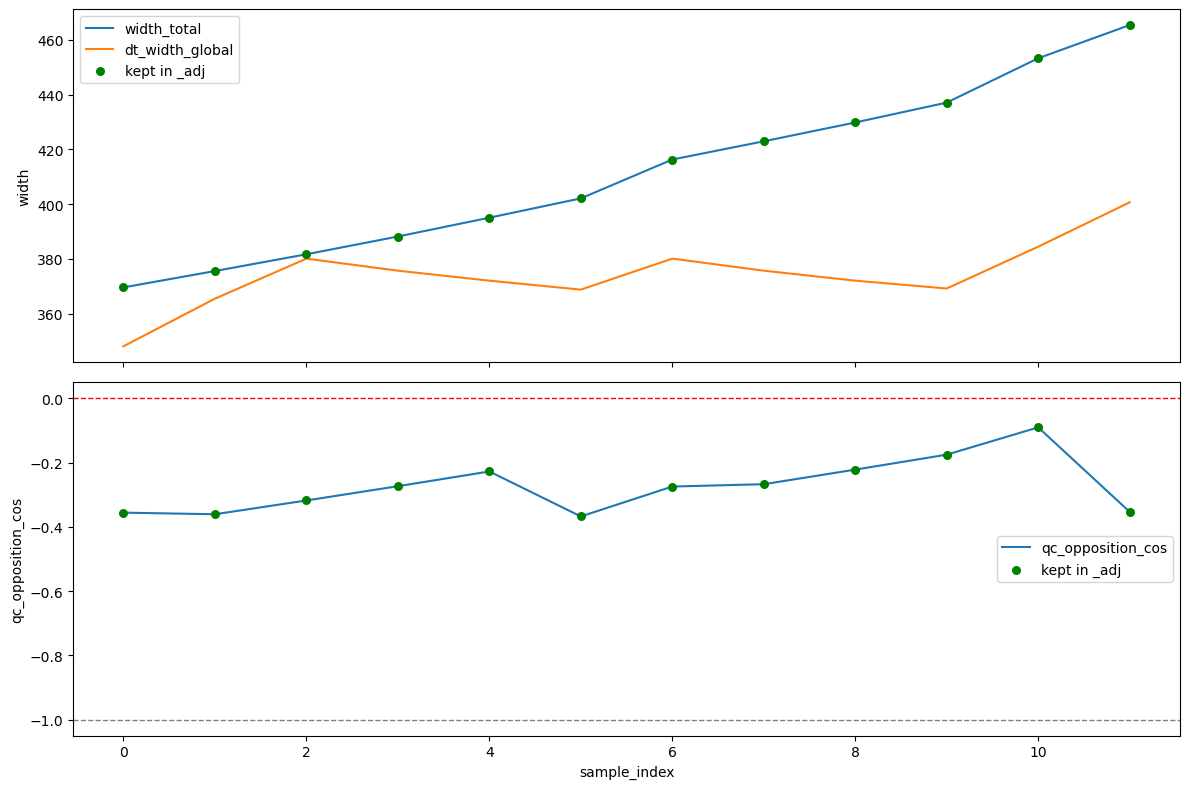

In [7]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

repo_root = Path("/Users/6256481/Code/river-hierarchy")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from network_variants.variant_generation import _trim_slice

state_dir = repo_root / "network_variants/output/56_indep__anchored/states/S006_unit_15/variant"
state_dir = Path("/Users/6256481/Code/river-hierarchy/network_variants/output/02_indep__anchored/states/S000_base/variant")

link_id = 30

manifest = json.loads((state_dir / "summary" / "variant_manifest.json").read_text())
directed_links_path = Path(manifest["output_paths"]["directed_links"])

families = pd.read_csv(state_dir / "widths" / "link_width_families.csv")
samples = pd.read_csv(state_dir / "widths" / "link_width_samples.csv")
links = gpd.read_file(directed_links_path)

link_row = families.loc[families["id_link"].eq(link_id)].iloc[0]
sample_df = (
    samples.loc[samples["id_link"].eq(link_id)]
    .copy()
    .sort_values("sample_index")
    .reset_index(drop=True)
)

xs = sample_df["x"].to_numpy(dtype=float)
ys = sample_df["y"].to_numpy(dtype=float)

if len(xs) <= 1:
    distances = np.array([0.0], dtype=float)
else:
    distances = np.insert(np.cumsum(np.sqrt(np.diff(xs) ** 2 + np.diff(ys) ** 2)), 0, 0.0)

total_widths = sample_df["width_total"].to_numpy(dtype=float)
trim = _trim_slice(total_widths, distances)

sample_df["in_adj"] = False
sample_df.loc[trim, "in_adj"] = True

print("directed_links_path:", directed_links_path)
print("trim slice:", trim)
print("samples kept in _adj:", int(sample_df["in_adj"].sum()), "of", len(sample_df))

display(
    sample_df.loc[:, [
        "sample_index",
        "in_adj",
        "width_invalid",
        "width_total",
        "width_wet",
        "width_dry",
        "dt_width_global",
        "qc_opposition_cos",
        "qc_relative_dt_diff",
        "qc_width_chord_diff",
    ]]
)

kept = sample_df.loc[sample_df["in_adj"]].copy()
print("kept samples with qc_opposition_cos > 0:", int((kept["qc_opposition_cos"] > 0).sum()), "of", len(kept))
print("kept samples with qc_opposition_cos >= 0:", int((kept["qc_opposition_cos"] >= 0).sum()), "of", len(kept))

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(sample_df["sample_index"], sample_df["width_total"], label="width_total")
axes[0].plot(sample_df["sample_index"], sample_df["dt_width_global"], label="dt_width_global")
axes[0].scatter(
    sample_df.loc[sample_df["in_adj"], "sample_index"],
    sample_df.loc[sample_df["in_adj"], "width_total"],
    color="green",
    s=30,
    label="kept in _adj",
    zorder=3,
)
axes[0].legend()
axes[0].set_ylabel("width")

axes[1].plot(sample_df["sample_index"], sample_df["qc_opposition_cos"], label="qc_opposition_cos")
axes[1].axhline(-1.0, color="gray", linestyle="--", linewidth=1)
axes[1].axhline(0.0, color="red", linestyle="--", linewidth=1)
axes[1].scatter(
    sample_df.loc[sample_df["in_adj"], "sample_index"],
    sample_df.loc[sample_df["in_adj"], "qc_opposition_cos"],
    color="green",
    s=30,
    label="kept in _adj",
    zorder=3,
)
axes[1].legend()
axes[1].set_xlabel("sample_index")
axes[1].set_ylabel("qc_opposition_cos")

plt.tight_layout()
plt.show()


Empty GeoDataFrame
Columns: [component_id, geometry_role, action, unit_ids, collapsed_selection_type, collapsed_selection_label, collapsed_unit_ids, collapsed_group_label, collapsed_unit_count, example_id, variant_id, geometry]
Index: []


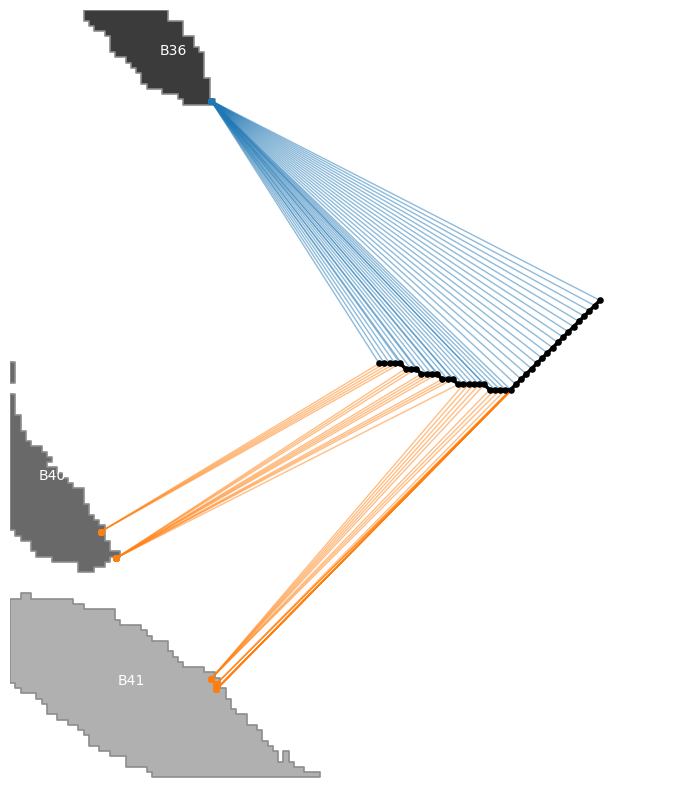

In [24]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.features import shapes
from rasterio.windows import from_bounds
from shapely.geometry import box, shape



def dt_view(state_dir, link_id, collapse = True):
    manifest = json.loads((state_dir / "summary" / "variant_manifest.json").read_text())
    directed_links = gpd.read_file(manifest["output_paths"]["directed_links"])
    samples = pd.read_csv(state_dir / "widths" / "link_width_samples.csv")
    edit_geoms = gpd.read_file(manifest["output_paths"]["edit_geometries"])

    link = directed_links.loc[directed_links["id_link"].eq(link_id)].copy()

    s = (
        samples.loc[samples["id_link"].eq(link_id)]
        .copy()
        .sort_values("sample_index")
        .reset_index(drop=True)
    )
    s_valid = s.loc[~s["width_invalid"].fillna(False)].iloc[::step].copy()

    # AOI from current plot contents
    xs = np.r_[link.total_bounds[[0, 2]], s_valid["x"], s_valid["left_bank_x"], s_valid["right_bank_x"]]
    ys = np.r_[link.total_bounds[[1, 3]], s_valid["y"], s_valid["left_bank_y"], s_valid["right_bank_y"]]
    pad = 150
    aoi = box(xs.min() - pad, ys.min() - pad, xs.max() + pad, ys.max() + pad)

    # Bank components actually used by this link's transects
    bank_ids = (
        pd.concat([s_valid["left_component_id"], s_valid["right_component_id"]])
        .dropna()
        .astype(int)
        .unique()
    )

    # Vectorize only those bank labels inside AOI
    bank_polys = []
    with rasterio.open(manifest["output_paths"]["bank_labels"]) as ds:
        win = from_bounds(*aoi.bounds, transform=ds.transform)
        arr = ds.read(1, window=win)
        transform = ds.window_transform(win)

        mask = np.isin(arr, bank_ids)
        for geom, val in shapes(arr.astype("int32"), mask=mask, transform=transform):
            val = int(val)
            if val > 1:
                bank_polys.append({"bank_id": val, "geometry": shape(geom)})

    banks = gpd.GeoDataFrame(bank_polys, crs=directed_links.crs)
    if not banks.empty:
        banks = banks.dissolve(by="bank_id").reset_index()
        banks = banks.clip(aoi)

    # Collapsed island geometry: actual added fill
    collapsed_island = (
        edit_geoms.loc[edit_geoms["geometry_role"].eq("edit")]
        .clip(aoi)
    )

    fig, ax = plt.subplots(figsize=(10, 10))

    # local bank polygons
    bankColors = ['#B0B0B0', '#696969', '#3B3B3B', "#3C3C3C"]
    if not banks.empty:
        banks['faceColor'] = bankColors[:banks.shape[0]]
        banks.plot(ax=ax, facecolor=banks['faceColor'], edgecolor="0.55", linewidth=1.2, zorder=1)
        for row in banks.itertuples():
            pt = row.geometry.representative_point()
            ax.text(pt.x, pt.y, f"B{row.bank_id}", fontsize=10, color="white", zorder=5)

    if collapse == True:
        print(collapsed_island)
        if not collapsed_island.empty:
            collapsed_island.plot(ax=ax, facecolor="gold", edgecolor="darkgoldenrod", alpha=0.35, zorder=1.5)
            for row in collapsed_island.itertuples():
                pt = row.geometry.representative_point()
                ax.text(pt.x, pt.y, fontsize=10, weight="bold", color="black", zorder=6)

    # target link centerline
    link.plot(ax=ax, color="black", linewidth=2.5, zorder=3)

    # bank legs
    for row in s_valid.itertuples():
        ax.plot([row.left_bank_x, row.x], [row.left_bank_y, row.y],
                color="tab:blue", alpha=0.5, linewidth=1, zorder=2)
        ax.plot([row.x, row.right_bank_x], [row.y, row.right_bank_y],
                color="tab:orange", alpha=0.5, linewidth=1, zorder=2)

    # sample and bank target points
    ax.scatter(s_valid["x"], s_valid["y"], s=14, color="black", label="center samples", zorder=4)
    ax.scatter(s_valid["left_bank_x"], s_valid["left_bank_y"], s=16, color="tab:blue", label="left bank targets", zorder=4)
    ax.scatter(s_valid["right_bank_x"], s_valid["right_bank_y"], s=16, color="tab:orange", label="right bank targets", zorder=4)

    # for row in s_valid.itertuples():
    #     ax.text(row.x, row.y, str(row.sample_index), fontsize=6, color="black")

    ax.set_xlim(aoi.bounds[0], aoi.bounds[2])
    ax.set_ylim(aoi.bounds[1], aoi.bounds[3])
    ax.set_aspect("equal")
    # ax.set_title(f"{state_dir.parent.name} | link {link_id} | bank targets + local banks")
    ax.axis("off")
    # ax.legend()
    plt.show()


state_dir = Path("/Users/6256481/Code/river-hierarchy/network_variants/output/05_indep__anchored/states/S036_unit_35/variant")
link_id = 102
# state_dir = Path("/Users/6256481/Code/river-hierarchy/network_variants/output/56_indep__anchored/states/S010_unit_8/variant")
# link_id = 19

state_dir = Path("/Users/6256481/Code/river-hierarchy/network_variants/output/02_indep__anchored/states/S000_base/variant")
link_id = 51
step = 1

dt_view(state_dir, link_id, collapse = True)

In [129]:
bad = s.loc[
    s["width_invalid"].fillna(False)
    | (s["qc_opposition_cos"] > -0.8)
    | (s["qc_relative_dt_diff"].abs() > 0.1)
].copy()

display(
    bad[[
        "sample_index",
        "left_component_id",
        "right_component_id",
        "d_left",
        "d_right",
        "width_total",
        "width_wet",
        "width_dry",
        "dt_width_global",
        "qc_opposition_cos",
        "qc_relative_dt_diff",
        "width_invalid",
    ]]
)


,sample_index,left_component_id,right_component_id,d_left,d_right,width_total,width_wet,width_dry,dt_width_global,qc_opposition_cos,qc_relative_dt_diff,width_invalid
5,5,523.0,197.0,435.759171,358.867981,794.627151,787.370896,0.000000,717.735961,-0.843408,0.107130,False
7,7,523.0,197.0,437.720955,369.165463,806.886418,799.583640,0.000000,738.330925,-0.787708,0.092852,False
8,8,523.0,197.0,433.232652,376.277193,809.509846,802.216058,0.000000,752.554386,-0.776556,0.075683,False
9,9,523.0,197.0,434.713372,381.787083,816.500455,809.211334,0.000000,763.574166,-0.746287,0.069314,False
10,10,523.0,197.0,430.442574,388.943391,819.385965,812.103162,0.000000,777.886782,-0.734386,0.053349,False
76,76,523.0,197.0,371.767287,456.347990,828.115277,711.476396,109.343320,743.534575,-0.898617,0.113755,False
77,77,523.0,197.0,370.540925,454.407701,824.948626,715.963493,101.717117,741.081849,-0.913391,0.113168,False
78,78,523.0,197.0,369.455459,452.577428,822.032887,708.643824,106.081270,738.910918,-0.927146,0.112493,False
79,79,523.0,197.0,368.512136,450.858511,819.370647,706.275641,105.810415,737.024272,-0.939831,0.111728,False
80,80,523.0,197.0,367.712050,449.252227,816.964277,700.449706,109.221401,735.424099,-0.951403,0.110875,False


## Network-Wide Junction Width Continuity Diagnostics

Use this section to inspect short unit-related links across one full base or variant network. The metrics below are designed to help review junction continuity, not to hard-apply a fix yet.


In [169]:
from pathlib import Path
import json
import sqlite3

import numpy as np
import pandas as pd


def get_review_settings(state_dir: Path):
    # --- review settings ---
    width_field = "wid_adj_wet"
    short_ratio_thresh = 1.0
    require_n_units_ge = 2
    require_both_junctions = True
    qc_opposition_warn = -0.8
    qc_relative_dt_warn = 0.1

    manifest = json.loads((state_dir / "summary" / "variant_manifest.json").read_text())
    families = pd.read_csv(state_dir / "widths" / "link_width_families.csv")
    samples = pd.read_csv(state_dir / "widths" / "link_width_samples.csv")

    RIVGRAPH_WIDTH_TRIM_MULTIPLIER = 1.1

    def _mark_trimmed_sample_rows(group: pd.DataFrame) -> pd.DataFrame:
        group = group.sort_values("sample_index").copy()
        n = len(group)
        if n == 0:
            group["used_in_trimmed_width"] = False
            return group

        widths = pd.to_numeric(group["width_total"], errors="coerce").to_numpy(dtype=float)
        xs = pd.to_numeric(group["x"], errors="coerce").to_numpy(dtype=float)
        ys = pd.to_numeric(group["y"], errors="coerce").to_numpy(dtype=float)

        if n <= 1 or not np.isfinite(widths[[0, -1]]).all():
            trim = slice(0, n)
        else:
            step = np.sqrt(np.diff(xs) ** 2 + np.diff(ys) ** 2)
            step = np.where(np.isfinite(step), step, 0.0)
            distances = np.insert(np.cumsum(step), 0, 0.0)
            revdistances = np.insert(np.cumsum(np.flipud(np.diff(distances))), 0, 0.0)
            start_index = int(np.argmin(np.abs(distances - widths[0] / 2.0 * RIVGRAPH_WIDTH_TRIM_MULTIPLIER)))
            end_index = int(
                len(distances)
                - np.argmin(np.abs(revdistances - widths[-1] / 2.0 * RIVGRAPH_WIDTH_TRIM_MULTIPLIER))
                - 1
            )
            trim = slice(0, n) if start_index >= end_index else slice(start_index, end_index)

        mask = np.zeros(n, dtype=bool)
        mask[trim] = True
        group["used_in_trimmed_width"] = mask
        return group

    samples = (
        samples.sort_values(["id_link", "sample_index"], kind="mergesort")
        .groupby("id_link", group_keys=False)
        .apply(_mark_trimmed_sample_rows)
        .reset_index(drop=True)
    )

    sample_qc = (
        samples.groupby("id_link", as_index=False)
        .agg(qc_mean_opposition_cos=("qc_opposition_cos", "mean"))
    )
    trimmed_qc_mask = samples["used_in_trimmed_width"].fillna(False)
    if "width_invalid" in samples.columns:
        trimmed_qc_mask &= ~samples["width_invalid"].fillna(False).astype(bool)
    sample_qc_trimmed = (
        samples.loc[trimmed_qc_mask]
        .groupby("id_link", as_index=False)
        .agg(
            qc_mean_opposition_cos_trimmed_from_samples=("qc_opposition_cos", "mean"),
            n_trimmed_qc_samples=("qc_opposition_cos", "count"),
        )
    )
    preferred_qc_trimmed_col = "qc_mean_opposition_cos_trimmed"
    has_trimmed_qc = preferred_qc_trimmed_col in families.columns

    with sqlite3.connect(manifest["output_paths"]["directed_links"]) as con:
        table = con.execute("select table_name from gpkg_contents").fetchone()[0]
        links = pd.read_sql_query(
            f"select id_link, id_us_node, id_ds_node, len, n_units, unit_ids from '{table}'",
            con,
        )

    family_cols = [
        "id_link",
        width_field,
        "wid_adj_total",
        "wid_p05_wet",
        "wid_p50_wet",
        "wid_p95_wet",
        "qc_min_opposition_cos",
        "qc_mean_relative_dt_diff",
        "qc_mean_opposition_cos_trimmed",
    ]
    family_cols = [c for c in family_cols if c in families.columns]

    frame = links.merge(families[family_cols], on="id_link", how="left")
    frame = frame.merge(sample_qc, on="id_link", how="left")
    frame = frame.merge(sample_qc_trimmed, on="id_link", how="left")
    if preferred_qc_trimmed_col not in frame.columns:
        frame[preferred_qc_trimmed_col] = frame["qc_mean_opposition_cos_trimmed_from_samples"]
    else:
        frame[preferred_qc_trimmed_col] = frame[preferred_qc_trimmed_col].fillna(frame["qc_mean_opposition_cos_trimmed_from_samples"])
    frame[width_field] = pd.to_numeric(frame[width_field], errors="coerce")
    frame["len"] = pd.to_numeric(frame["len"], errors="coerce")
    frame["len_over_width"] = frame["len"] / frame[width_field]

    # Node degree in the directed link graph.
    node_edges = pd.concat(
        [
            frame[["id_link", "id_us_node"]].rename(columns={"id_us_node": "node"}),
            frame[["id_link", "id_ds_node"]].rename(columns={"id_ds_node": "node"}),
        ],
        ignore_index=True,
    )
    node_degree = node_edges.groupby("node")["id_link"].nunique().to_dict()
    frame["us_degree"] = frame["id_us_node"].map(node_degree)
    frame["ds_degree"] = frame["id_ds_node"].map(node_degree)
    frame["both_junctions"] = frame["us_degree"].ge(3) & frame["ds_degree"].ge(3)

    # Node-level width continuity using the selected width field.
    node_in_sum = frame.groupby("id_ds_node")[width_field].sum(min_count=1).to_dict()
    node_out_sum = frame.groupby("id_us_node")[width_field].sum(min_count=1).to_dict()
    node_in_count = frame.groupby("id_ds_node")["id_link"].nunique().to_dict()
    node_out_count = frame.groupby("id_us_node")["id_link"].nunique().to_dict()

    frame["us_in_width_sum"] = frame["id_us_node"].map(node_in_sum)
    frame["us_out_width_sum"] = frame["id_us_node"].map(node_out_sum)
    frame["ds_in_width_sum"] = frame["id_ds_node"].map(node_in_sum)
    frame["ds_out_width_sum"] = frame["id_ds_node"].map(node_out_sum)
    frame["us_in_count"] = frame["id_us_node"].map(node_in_count)
    frame["us_out_count"] = frame["id_us_node"].map(node_out_count)
    frame["ds_in_count"] = frame["id_ds_node"].map(node_in_count)
    frame["ds_out_count"] = frame["id_ds_node"].map(node_out_count)

    frame["us_node_out_over_in"] = frame["us_out_width_sum"] / frame["us_in_width_sum"]
    frame["ds_node_out_over_in"] = frame["ds_out_width_sum"] / frame["ds_in_width_sum"]

    def symmetric_ratio(series: pd.Series) -> pd.Series:
        inv = 1.0 / series
        return pd.concat([series, inv], axis=1).max(axis=1)

    frame["us_node_continuity_dev"] = symmetric_ratio(frame["us_node_out_over_in"])
    frame["ds_node_continuity_dev"] = symmetric_ratio(frame["ds_node_out_over_in"])
    frame["max_node_continuity_dev"] = frame[["us_node_continuity_dev", "ds_node_continuity_dev"]].max(axis=1)

    # Link-local context at the two adjacent nodes.
    frame["link_share_of_us_out"] = frame[width_field] / frame["us_out_width_sum"]
    frame["link_share_of_ds_in"] = frame[width_field] / frame["ds_in_width_sum"]
    frame["link_vs_us_in_sum"] = frame[width_field] / frame["us_in_width_sum"]
    frame["link_vs_ds_out_sum"] = frame[width_field] / frame["ds_out_width_sum"]

    frame["qc_opposition_warn"] = frame["qc_min_opposition_cos"] > qc_opposition_warn
    frame["qc_relative_dt_warn"] = frame["qc_mean_relative_dt_diff"].abs() > qc_relative_dt_warn
    frame["qc_warn_any"] = frame["qc_opposition_warn"] | frame["qc_relative_dt_warn"]

    structural_mask = frame["n_units"].fillna(0).ge(require_n_units_ge) & frame["len_over_width"].lt(short_ratio_thresh)
    if require_both_junctions:
        structural_mask &= frame["both_junctions"].fillna(False)
    frame["structural_candidate"] = structural_mask

    review_cols = [
        "id_link",
        "structural_candidate",
        "both_junctions",
        "n_units",
        "len",
        width_field,
        "len_over_width",
        "us_degree",
        "ds_degree",
        "us_in_count",
        "us_out_count",
        "ds_in_count",
        "ds_out_count",
        "us_node_out_over_in",
        "ds_node_out_over_in",
        "us_node_continuity_dev",
        "ds_node_continuity_dev",
        "max_node_continuity_dev",
        "link_share_of_us_out",
        "link_share_of_ds_in",
        "link_vs_us_in_sum",
        "link_vs_ds_out_sum",
        "qc_mean_opposition_cos",
        "qc_mean_opposition_cos_trimmed_from_samples",
        "qc_min_opposition_cos",
        "qc_mean_relative_dt_diff",
        "qc_warn_any",
        "qc_mean_opposition_cos_trimmed"
    ]
    review_cols = [c for c in review_cols if c in frame.columns]

    review = frame.loc[frame["structural_candidate"], review_cols].copy()
    review = review.sort_values(
        ["len_over_width", "max_node_continuity_dev", "qc_warn_any"],
        ascending=[True, False, False],
    ).reset_index(drop=True)

    full_table = frame.loc[:, review_cols].copy()
    full_table = full_table.sort_values(
        ["structural_candidate", "len_over_width", "max_node_continuity_dev", "qc_warn_any"],
        ascending=[False, True, False, False],
    ).reset_index(drop=True)

    summary = {
        "state_dir": str(state_dir),
        "n_links": int(len(frame)),
        "n_structural_candidates": int(review.shape[0]),
        "width_field": width_field,
        "short_ratio_thresh": short_ratio_thresh,
        "has_trimmed_qc": bool(has_trimmed_qc),
    }

    return summary, review, full_table
# display(pd.Series(summary, name="network_summary"))
# display(review)
# display(full_table)
# --- choose network ---
state_dir = Path("/Users/6256481/Code/river-hierarchy/network_variants/output/03_indep__anchored/states/S000_base/variant")
summary, review, full_table = get_review_settings(state_dir)

/var/folders/bs/xx1t3fn91jl3k26fn1pndd_c0000gn/T/ipykernel_37666/183925994.py:58: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(_mark_trimmed_sample_rows)


In [170]:
def filter():
    A_cols = [
        'id_link',
        'n_units',
        'len_over_width',
        'us_dev',
        'ds_dev',
        'node_dev_max',
        'qc_mean_opposition_cos_trimmed_from_samples',
        'qc_mean_opposition_cos',
    ]
    full_table["us_dev"] = (full_table["us_node_out_over_in"] - 1).abs()
    full_table["ds_dev"] = (full_table["ds_node_out_over_in"] - 1).abs()
    full_table["node_dev_max"] = full_table[["us_dev", "ds_dev"]].max(axis=1)
    A = full_table[A_cols].copy()
    A = A[(A["n_units"] > 0) & (A["len_over_width"] < 1.5)]
    return A
# A = filter()
# B = filter()
C = filter()

# A['n_units'] = A['n_units'].astype(float).copy()
# A['us_node_out_over_in'] = abs(A['us_node_out_over_in'] -1) 
# A['ds_node_out_over_in'] = abs(A['ds_node_out_over_in'] -1) 

In [172]:
C['id_link'].to_list()

[28, 79, 69, 41, 68, 85, 59, 72, 84, 56, 77, 50, 76, 66, 70]

In [171]:
C.sort_values('id_link')



,id_link,n_units,len_over_width,us_dev,ds_dev,node_dev_max,qc_mean_opposition_cos_trimmed_from_samples,qc_mean_opposition_cos
0,28,2,0.608515,0.411624,0.359852,0.411624,-0.830665,-0.830665
6,41,1,0.399152,1.433287,0.285206,1.433287,0.199241,0.199241
15,50,1,1.059373,0.381577,0.197786,0.381577,-0.425366,-0.425366
13,56,1,0.914487,0.098263,0.194621,0.194621,-0.686598,-0.686598
10,59,1,0.627979,0.040496,0.088795,0.088795,-0.827261,-0.827261
17,66,1,1.109686,1.008898,0.044234,1.008898,-0.910309,-0.910309
7,68,1,0.405551,1.008898,0.670805,1.008898,0.010862,0.010862
2,69,1,0.106366,1.096407,0.171767,1.096407,-0.506386,-0.506386
20,70,2,1.495824,1.096407,0.253021,1.096407,-0.420565,-0.420565
11,72,1,0.758983,0.130636,0.449893,0.449893,-0.764568,-0.764568


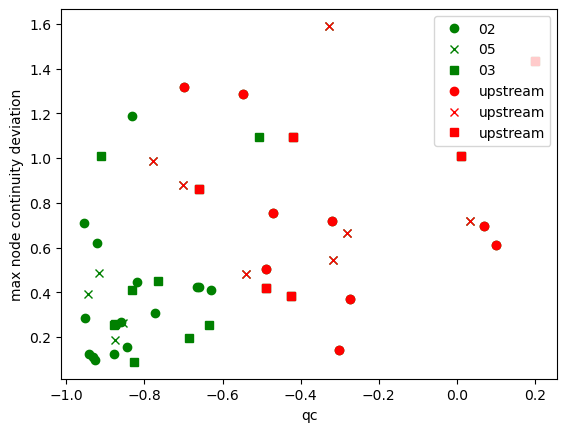

In [185]:
AA = A[A['id_link'].isin([51, 30, 14, 7, 65, 74, 41,15, 33])]
BB = B[B['id_link'].isin([8, 70, 78, 86, 100, 109, 75])]#75
CC = C[C['id_link'].isin([41, 50, 68, 70, 76, 84])]# 69, 79, 72
 
plt.plot(A['qc_mean_opposition_cos_trimmed_from_samples'], A['node_dev_max'], 'o', color = 'green', label = '02')
plt.plot(B['qc_mean_opposition_cos_trimmed_from_samples'], B['node_dev_max'], 'x', color = 'green', label = '05')
plt.plot(C['qc_mean_opposition_cos_trimmed_from_samples'], C['node_dev_max'], 's', color = 'green', label = '03')
plt.plot(AA['qc_mean_opposition_cos_trimmed_from_samples'], AA['node_dev_max'], 'o', label='upstream', color = 'red')
plt.plot(BB['qc_mean_opposition_cos_trimmed_from_samples'], BB['node_dev_max'], 'x', label='upstream', color = 'red')
plt.plot(CC['qc_mean_opposition_cos_trimmed_from_samples'], CC['node_dev_max'], 's', label='upstream', color = 'red')
plt.xlabel('qc')
plt.ylabel('max node continuity deviation')
plt.legend()
plt.show()

In [ ]:

B = A[A['id_link'].isin([51, 30, 14, 7, 65, 74, 41,15])]

plt.plot(A['qc_mean_opposition_cos_trimmed_from_samples'], A['node_dev_max'], 'o', label='upstream')
plt.plot(B['qc_mean_opposition_cos_trimmed_from_samples'], B['node_dev_max'], 'o', label='upstream')
plt.xlabel('qc')
plt.ylabel('max node continuity deviation')